# 01 - EDA: Klasifikasi Risiko Diabetes Menggunakan Naive Bayes

## 1. Ide (Topik)

**Klasifikasi Risiko Diabetes Menggunakan Naive Bayes Berdasarkan Data
Diagnostik Pasien.**

## 2. Deskripsi Ide

Proyek membangun model klasifikasi **Gaussian Naive Bayes** untuk
memprediksi kategori diabetes seorang pasien.

> **Riwayat revisi setelah presentasi dosen pembimbing:**
> 1. Target awal `Outcome` biner -> 3 kelas `GlucoseRisk` dari ambang
>    batas klinis `Glucose` saja.
> 2. Dicari faktor di luar glukosa -> target diganti `InsulinResistance`,
>    proxy resistensi insulin dari `Glucose` x `Insulin`, karena skema
>    "Tipe 1/2/3/Gestasional" dari artikel populer bukan klasifikasi
>    medis resmi dan dataset publik lain yang punya label tipe diabetes
>    ternyata data sintetis tak kompatibel untuk digabung.
> 3. **Revisi ini:** dicari dataset nyata (bukan sintetis) yang
>    pasiennya benar-benar didiagnosis dengan tipe diabetes berbeda,
>    dengan tetap memakai Pima. Ditemukan **dataset Gestational
>    Diabetes Mellitus (GDM)** -- 3.525 pasien hamil nyata dari rumah
>    sakit di India, dengan label diagnosis klinis asli (GDM / Non-GDM).
>    Pima + GDM digabung menjadi target **`DiagnosisType`** 3 kelas
>    berbasis **diagnosis asli kedua studi**, bukan ambang batas yang
>    dihitung sendiri:
>
> | Kelas | Sumber | Dasar label |
> | --- | --- | --- |
> | Normal | Pima + GDM | `Outcome=0` (Pima) atau `Non-GDM` (GDM) |
> | Tipe 2 | Pima | `Outcome=1` (diagnosis T2D asli studi Pima) |
> | Gestasional | GDM | `Class=GDM` (diagnosis GDM asli studi tsb.) |
>
> Metodologi penggabungan mengikuti pendekatan Rasheed dkk. (Scientific
> Reports, 2026): union kolom yang benar-benar terukur di kedua
> dataset. Lihat `src/merge.py` untuk detail dan alasan setiap
> keputusan desain.


## 3. Analisis Permasalahan

### 3.1 Mengapa Union Kolom Dibatasi pada Lima Atribut

Pima (8 atribut: `Pregnancies`, `Glucose`, `BloodPressure`,
`SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`)
dan GDM (17 atribut, termasuk `HDL`, `Hemoglobin`, `Family History`,
`PCOS`, dll.) hanya punya **lima** atribut dengan padanan konsep
langsung: `Age`, jumlah kehamilan (`Pregnancies`), `BMI`, tekanan
darah diastolik (`BloodPressure`), dan kadar glukosa OGTT (`Glucose`).
Union penuh seluruh kolom kedua dataset (seperti pada paper acuan,
yang memakai MICE untuk mengisi kolom yang strukturnya hilang total di
satu sumber) dipertimbangkan, tetapi **tidak dipakai** pada proyek ini
-- terlalu berat untuk diaudit asumsinya pada skala tugas kuliah.
Konsekuensinya: `SkinThickness`, `Insulin`, `DiabetesPedigreeFunction`
(unik Pima) dan `HDL`, `Hemoglobin`, `Family History`, dll. (unik GDM)
tidak dipakai pada model gabungan -- trade-off eksplisit, bukan
keterbatasan tersembunyi.

### 3.2 Keterbatasan Paling Penting: Status Kehamilan sebagai Perancu

Pasien Pima **tidak selalu sedang hamil** saat diperiksa, sedangkan
**seluruh pasien GDM, menurut definisi, sedang hamil**. Kehamilan
secara fisiologis mengubah resistensi insulin, BMI efektif, dan
tekanan darah. Ini berarti model berpotensi mempelajari **perbedaan
sumber data / status kehamilan**, bukan murni perbedaan tipe diabetes.
Bagian 7 notebook ini membuktikan kekhawatiran ini secara empiris,
bukan hanya dugaan teoretis.


## 4. Sumber Data

**Dataset 1 - Pima Indians Diabetes Database.** 768 pasien perempuan
Pima Indian usia >= 21 tahun, 8 atribut, label `Outcome` (diagnosis
T2D biner). <https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset>

**Dataset 2 - Gestational Diabetes Mellitus (GDM) Data Set.** 3.525
pasien hamil (data rumah sakit di India), 17 atribut, label
`Class Label(GDM /Non GDM)` (diagnosis GDM biner). Sumber: Sumathi
Santhosh, Kaggle -- <https://www.kaggle.com/datasets/sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set>,
diunduh dari salinan resmi penulis paper rujukan di GitHub
(`abeereg/Diabetes`).


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data, verify_reference_statistics, verify_class_distribution
from src.preprocessing import ZERO_AS_MISSING_COLUMNS, mark_missing, count_missing
from src.gdm_loader import load_gdm_data, count_missing_gdm, GDM_TO_PIMA_COLUMNS, CLASS_COL

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
GDM_PATH = PROJECT_ROOT / "data" / "gdm_dataset.xlsx"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 100)

df_pima = load_data(DATA_PATH)
df_gdm = load_gdm_data(GDM_PATH)
print(f"Pima: {df_pima.shape} | GDM: {df_gdm.shape}")


Pima: (768, 9) | GDM: (3525, 17)


### 4.1 Pratinjau Kedua Dataset


In [2]:
df_pima.head()


   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]

In [3]:
df_gdm.head()


   Case Number  Age  ...  Prediabetes  Class Label(GDM /Non GDM)
0            1   22  ...            0                          0
1            2   26  ...            0                          0
2            3   29  ...            0                          0
3            4   28  ...            0                          0
4            5   21  ...            0                          0

[5 rows x 17 columns]

### 4.2 Verifikasi Integritas Pima


In [4]:
selisih_statistik = verify_reference_statistics(df_pima)
verifikasi_kelas = verify_class_distribution(df_pima)
print("Selisih statistik vs dokumen sumber:", selisih_statistik or "tidak ada (cocok)")
print("Distribusi Outcome:", verifikasi_kelas["distribusi_aktual"])


Selisih statistik vs dokumen sumber: tidak ada (cocok)
Distribusi Outcome: {0: 500, 1: 268}


### 4.3 Nilai Hilang pada Kedua Dataset

Pima memakai nilai 0 sebagai sentinel data hilang pada lima kolom
fisiologis (dibahas rinci pada proyek-proyek revisi sebelumnya). GDM
sudah memakai `NaN` eksplisit.


In [5]:
df_ditandai = mark_missing(df_pima)
print("Nilai hilang Pima (dari nilai 0):")
for kolom, jumlah in count_missing(df_ditandai).items():
    print(f"  {kolom:15s}: {jumlah:3d} ({jumlah/len(df_pima)*100:.1f}%)")

print()
print("Nilai hilang GDM (NaN asli, hanya 5 kolom yang dipakai bersama Pima):")
for kolom, jumlah in count_missing_gdm(df_gdm).items():
    print(f"  {kolom:28s}: {jumlah:4d} ({jumlah/len(df_gdm)*100:.1f}%)")


Nilai hilang Pima (dari nilai 0):
  Glucose        :   5 (0.7%)
  BloodPressure  :  35 (4.6%)
  SkinThickness  : 227 (29.6%)
  Insulin        : 374 (48.7%)
  BMI            :  11 (1.4%)

Nilai hilang GDM (NaN asli, hanya 5 kolom yang dipakai bersama Pima):
  Age                         :    0 (0.0%)
  No of Pregnancy             :    0 (0.0%)
  BMI                         : 1081 (30.7%)
  Dia BP                      :    0 (0.0%)
  OGTT                        :  513 (14.6%)


## 5. Distribusi Label Asli Kedua Dataset


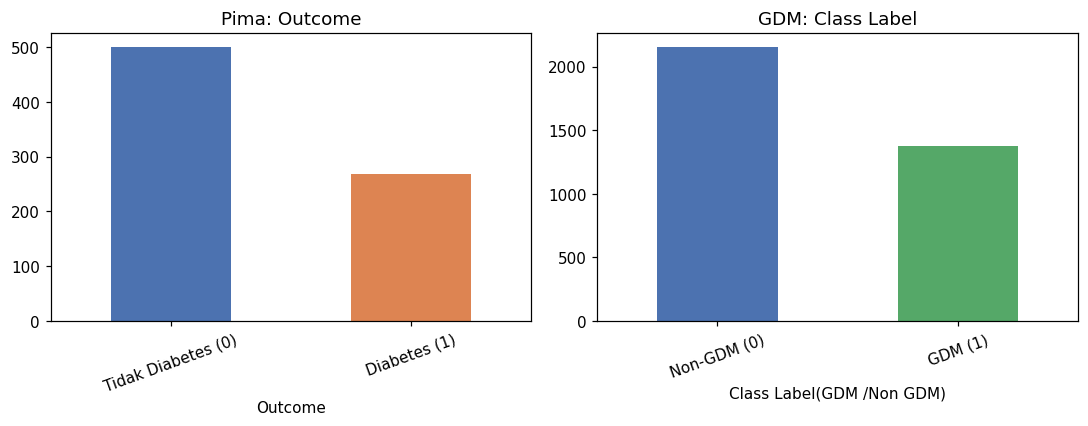

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df_pima["Outcome"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Pima: Outcome")
axes[0].set_xticklabels(["Tidak Diabetes (0)", "Diabetes (1)"], rotation=20)

df_gdm[CLASS_COL].value_counts().sort_index().plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868"])
axes[1].set_title("GDM: Class Label")
axes[1].set_xticklabels(["Non-GDM (0)", "GDM (1)"], rotation=20)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_source_label_distributions.png", dpi=150)
plt.show()


## 6. Rentang Nilai pada Lima Atribut yang Dipakai Bersama

Sebelum digabung, penting memeriksa apakah rentang nilai kedua dataset
sebanding -- bukan sekadar nama kolom yang mirip.


In [7]:
perbandingan = pd.DataFrame({
    "Pima_min": [df_pima["Age"].min(), df_pima["Pregnancies"].min(), df_pima["BMI"].replace(0, np.nan).min(),
                 df_pima["BloodPressure"].replace(0, np.nan).min(), df_pima["Glucose"].replace(0, np.nan).min()],
    "Pima_max": [df_pima["Age"].max(), df_pima["Pregnancies"].max(), df_pima["BMI"].max(),
                 df_pima["BloodPressure"].max(), df_pima["Glucose"].max()],
    "GDM_min": [df_gdm["Age"].min(), df_gdm["No of Pregnancy"].min(), df_gdm["BMI"].min(),
                df_gdm["Dia BP"].min(), df_gdm["OGTT"].min()],
    "GDM_max": [df_gdm["Age"].max(), df_gdm["No of Pregnancy"].max(), df_gdm["BMI"].max(),
                df_gdm["Dia BP"].max(), df_gdm["OGTT"].max()],
}, index=["Age", "Pregnancies", "BMI", "BloodPressure", "Glucose"])
perbandingan


               Pima_min  Pima_max  GDM_min  GDM_max
Age                21.0      81.0     20.0     45.0
Pregnancies         0.0      17.0      1.0      4.0
BMI                18.2      67.1     13.3     45.0
BloodPressure      24.0     122.0     60.0    124.0
Glucose            44.0     199.0     80.0    403.0

Rentang nilai cukup sebanding untuk `BMI` dan `BloodPressure`. `Age`
Pima jauh lebih lebar (21-81 vs 20-45 GDM) -- wajar, Pima bukan studi
khusus usia reproduktif. `Glucose`/`OGTT` GDM mencapai 403 vs Pima
hanya sampai 199 -- kriteria diagnostik OGTT kehamilan memang berbeda
dari kriteria non-hamil standar.


## 7. Pembuktian Empiris: Status Kehamilan sebagai Perancu

Bagian ini menguji langsung kekhawatiran pada bagian 3.2: apakah
pasien "Normal" dari kedua sumber benar-benar sebanding, atau justru
berbeda sistematis karena perbedaan studi (bukan perbedaan tipe
diabetes).


In [8]:
normal_pima = df_pima[df_pima["Outcome"] == 0]
normal_gdm = df_gdm[df_gdm[CLASS_COL] == 0]

perbandingan_normal = pd.DataFrame({
    "Pima (Outcome=0)": [normal_pima["Age"].mean(), normal_pima["BMI"].replace(0, np.nan).mean(), normal_pima["Pregnancies"].mean()],
    "GDM (Non-GDM)": [normal_gdm["Age"].mean(), normal_gdm["BMI"].mean(), normal_gdm["No of Pregnancy"].mean()],
}, index=["Age (rata-rata)", "BMI (rata-rata)", "Pregnancies (rata-rata)"]).round(2)
perbandingan_normal


                         Pima (Outcome=0)  GDM (Non-GDM)
Age (rata-rata)                     31.19          30.38
BMI (rata-rata)                     30.86          23.69
Pregnancies (rata-rata)              3.30           1.94

**Terbukti ada perbedaan sistematis:** BMI rata-rata pasien "Normal"
Pima (30,9) jauh lebih tinggi daripada GDM (23,7) -- selisih 7 poin,
bukan selisih kecil. Ini kemungkinan besar mencerminkan perbedaan
populasi penelitian (Pima Indian dengan prevalensi obesitas tinggi,
vs populasi studi GDM di India) dan/atau efek status kehamilan,
**bukan** perbedaan "tingkat kesehatan" yang relevan dengan tipe
diabetes. Konsekuensinya: model pada `03_GaussianNB` berisiko memakai
`BMI` sebagian untuk menebak **sumber data**, bukan murni tipe
diabetes. Ini didokumentasikan sebagai keterbatasan utama dan
dibuktikan lebih lanjut pada `04_Evaluation`, bukan disembunyikan.


## 8. Korelasi Antar Atribut (Lima Fitur Bersama)

Diperiksa pada Pima saja (satu-satunya dataset dengan seluruh delapan
atribut asli) sebagai dasar diskusi asumsi independensi Naive Bayes,
dipertahankan dari revisi sebelumnya karena tetap relevan untuk lima
atribut yang dipakai bersama.


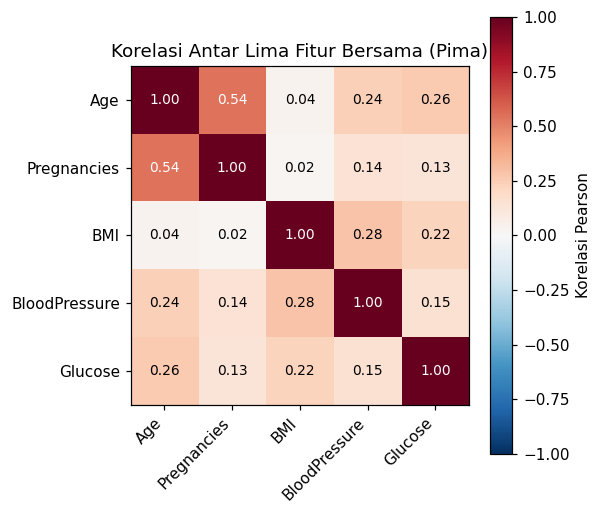

In [9]:
fitur_bersama = ["Age", "Pregnancies", "BMI", "BloodPressure", "Glucose"]
korelasi = df_pima[fitur_bersama].corr(method="pearson")

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(fitur_bersama)))
ax.set_yticks(range(len(fitur_bersama)))
ax.set_xticklabels(fitur_bersama, rotation=45, ha="right")
ax.set_yticklabels(fitur_bersama)
for i in range(len(fitur_bersama)):
    for j in range(len(fitur_bersama)):
        ax.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(korelasi.iloc[i, j]) > 0.5 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Korelasi Pearson")
ax.set_title("Korelasi Antar Lima Fitur Bersama (Pima)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_correlation_heatmap.png", dpi=150)
plt.show()


`Age` dan `Pregnancies` berkorelasi 0,54 -- pelanggaran asumsi
independensi yang tetap relevan untuk model gabungan ini. Korelasi
lain relatif rendah pada subset lima fitur ini.

**Lanjut ke `02_Preprocessing.ipynb`** untuk pembersihan kedua dataset
dan penggabungannya menjadi target `DiagnosisType` 3 kelas.
